<a href="https://colab.research.google.com/github/Lynna5639582/Lynna5639582-DataScience-GenAI-Submissions/blob/main/Practice_Data_Set_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
df = pd.read_csv('heart_disease_uci.csv')

Saving heart_disease_uci.csv to heart_disease_uci.csv


In [6]:
print('Shape:', df.shape)
print(df.head())
print('\nMissing values:\n', df.isna().sum())
print('\nTarget counts:\n', df['num'].value_counts())

Shape: (920, 16)
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             norma

In [7]:
# To prepare our features (X), we drop the target column 'num'
X = df.drop(columns=['num'])
y = df['num']
print('X:', X.shape, 'y:', y.shape)

X: (920, 15) y: (920,)


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Ensure we use the encoded features
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Split using the encoded dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=4567, stratify=y
)

# Scale the features using training data ONLY
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training shape:', X_train_scaled.shape)
print('Scaled test shape:', X_test_scaled.shape)

Scaled training shape: (736, 22)
Scaled test shape: (184, 22)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer

# Impute missing values (NaNs) using the median of each column
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Re-scale the imputed training features for Logistic Regression
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=4567),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=4567, n_jobs=-1),
    'GBDT': GradientBoostingClassifier(n_estimators=80, random_state=4567),
}

for name, model in models.items():
    # Logistic Regression uses scaled features, others use unscaled (but imputed) features
    training_features = X_train_scaled if name == 'Logistic Regression' else X_train_imputed
    model.fit(training_features, y_train)
    print(name, 'trained')

Logistic Regression trained
Random Forest trained
GBDT trained


In [13]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

results = []
for name, model in models.items():
    for split, features, target in [
        ('Train', X_train_scaled if name == 'Logistic Regression' else X_train_imputed, y_train),
        ('Test', X_test_scaled if name == 'Logistic Regression' else X_test_imputed, y_test),
    ]:
        pred = model.predict(features)
        precision, recall, f1, _ = precision_recall_fscore_support(
            target, pred, average='macro', zero_division=0
        )
        results.append({'Model': name, 'Split': split,
                        'Accuracy': accuracy_score(target, pred),
                        'Macro Precision': precision, 'Macro Recall': recall,
                        'Macro F1': f1})
results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Split,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,Train,0.648,0.528,0.462,0.480
1,Logistic Regression,Test,0.674,0.433,0.432,0.427
2,Random Forest,Train,1.000,1.000,1.000,1.000
3,Random Forest,Test,0.663,0.547,0.449,0.466
4,GBDT,Train,0.935,0.950,0.917,0.932
5,GBDT,Test,0.636,0.376,0.380,0.373


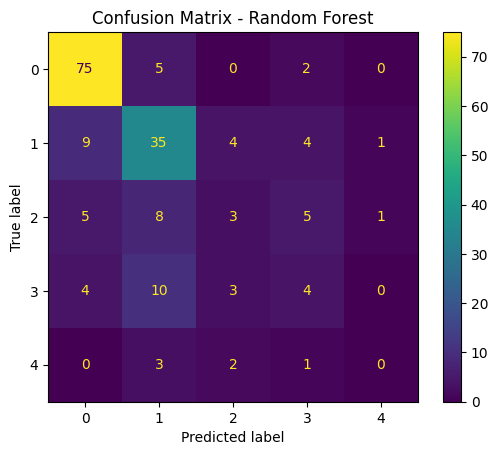

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import GradientBoostingClassifier
import matplotlib.pyplot as plt

# Re-initialize and fit the GBDT model locally using imputed training features
best_model = GradientBoostingClassifier(n_estimators=80, random_state=4567)
best_model.fit(X_train_imputed, y_train)

# GBDT uses non-scaled but imputed features
test_features = X_test_imputed

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, best_model.predict(test_features))
plt.title("Confusion Matrix - Random Forest")
plt.show()